# Nested-CV regression workflow

Linear and nonlinear regression with Optuna-based hyperparameter optimization, feature selection, and repeated nested cross-validation.

Created by: Pauline Bianchi (May 1, 2026)  
Edited by: Samantha Sloane and Pauline Bianchi  
Last update: November 2, 2026 
Sigman Lab, University of Utah, Version 1.1

The notebook compares several regression models using:

- repeated nested cross-validation, where the outer loop estimates generalization performance and the inner loop evaluates Optuna configurations;
- joint optimization of model hyperparameters and feature-selection strategy (SelectKBest, Lasso, Random Forest, or RFE);
- leakage-safe feature-correlation filtering inside every cross-validation fold;
- ensemble predictions obtained by averaging all outer-fold pipelines;
- optional Excel and figure export;
- optional evaluation on completely unseen external-test and virtual-screening datasets.

Most implementation details are contained in `bo_regression_functions.py`. This script must be placed in the same folder as the notebook. This workflow relies on the `bo_env` environment.

**For normal use, edit only the configuration cell in Section 3 (optionally cells 9 and 10 for external test and virtual screening), then run the notebook from top to bottom.**

## 1. Setup
Imports, warnings and a small helper used to label notebook tables.


In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from bo_regression_functions import (
    combine_training_and_external_predictions,
    compute_ensemble_shap,
    compute_feature_target_correlations,
    evaluate_external_dataset,
    export_workflow_results,
    load_regression_data,
    make_feature_pairs,
    plot_correlation_heatmap,
    plot_ensemble_shap,
    plot_external_overlay,
    plot_feature_frequency,
    plot_feature_histograms,
    plot_feature_pairs,
    plot_feature_target_correlations,
    plot_feature_target_scatter,
    plot_full_ensemble_parity,
    plot_model_metric_comparison,
    plot_model_prediction_comparison,
    plot_oof_parity,
    plot_overfitting_gap,
    plot_selector_frequency,
    plot_target_distribution,
    plot_target_split_distribution,
    plot_virtual_screening_distribution,
    run_nested_regression,
    save_ensemble_shap_results,
    save_external_results)

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=ConvergenceWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in divide")

def show_table(title, description, dataframe, rows=None):
    """Display a labelled notebook table with an optional row limit."""
    display(Markdown(f"### {title}\n{description}"))
    if rows is not None:
        display(dataframe.head(rows))
    else:
        display(dataframe)


/home/pbianchi/miniconda3/envs/bo_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Optional quick model check
Optional quick check: run this cell and only change the input and output data. It provides a preliminary model search and data-distribution evaluation and can be skipped without affecting the full workflow below. Note that Neural Network ("NN") is not included.

Loaded dataset: 10 rows, 18 features.

Starting MLR
  Fold 1/2
  Fold 2/2

Starting Ridge
  Fold 1/2
  Fold 2/2

Starting Lasso
  Fold 1/2
  Fold 2/2

Starting BRR
  Fold 1/2
  Fold 2/2

Starting KRR
  Fold 1/2
  Fold 2/2

Starting SVR
  Fold 1/2
  Fold 2/2

Starting KNN
  Fold 1/2
  Fold 2/2

Starting RF
  Fold 1/2
  Fold 2/2

Starting XGB
  Fold 1/2
  Fold 2/2
Nested cross-validation done.


### Model ranking from mean validation predictions
Primary comparison table. Models are ranked using the selected regression metric across repeated outer validation folds.

,Model,Model_selection_metric,R2_mean_oof_prediction_per_sample,RMSE_mean_oof_prediction_per_sample,MAE_mean_oof_prediction_per_sample,r2_mean_prediction,rmse_mean_prediction,mae_mean_prediction
3,Lasso,r2,0.723148,1.967051,1.248004,0.723148,1.967051,1.248004
6,Ridge,r2,0.702140,2.040318,1.720710,0.702140,2.040318,1.720710
1,KNN,r2,0.323578,3.074682,2.296574,0.323578,3.074682,2.296574
0,BRR,r2,0.216582,3.308935,2.232128,0.216582,3.308935,2.232128
7,SVR,r2,0.184870,3.375241,2.485824,0.184870,3.375241,2.485824
4,MLR,r2,0.157973,3.430476,2.370779,0.157973,3.430476,2.370779
8,XGB,r2,-0.038853,3.810382,2.942222,-0.038853,3.810382,2.942222
5,RF,r2,-0.042070,3.816276,2.954885,-0.042070,3.816276,2.954885
2,KRR,r2,-2.688897,7.180252,3.293944,-2.688897,7.180252,3.293944


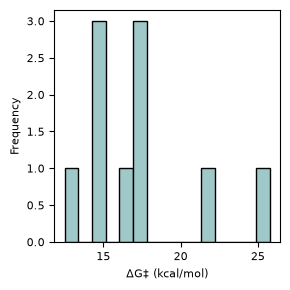

PosixPath('Results/workflow_example_261102_regression/target_distribution_workflow_example_260814_regression.svg')

In [2]:
# Input data
excel_file = Path("./InputData/Example.xlsx")
sheet_name = "Model"
target_column = "ΔG‡ (kcal/mol)"
id_columns = ["Nitroso"]
drop_columns = ["Nitroso","G(Nu) (Ha)","G(nitroso) (Ha)","G(TS) (Ha)","G(TS_true) (Ha)"]

# Output directory and optionally save & show results and figures (True/False)
results_dir = Path("./Results/workflow_example_261102_regression")
output_prefix = "workflow_example_260814_regression"
save_excel = True
save_figures = True
show_figures = True

# Performance, feature-selection and reproducibility options
rfe_step = 0.1
n_jobs = 4
one_se = True # If True, select the smallest model within one standard error of the best inner-CV score.
round_digits = 15

# --------------------------------------------------------------------------------------------------------------
# EDIT ABOVE THIS LINE
# --------------------------------------------------------------------------------------------------------------

results_dir.mkdir(parents=True, exist_ok=True)
show_summary_tables = True

# Load the dataset and display a summary of rows, features, and metadata
X, y, metadata = load_regression_data( excel_file=excel_file, sheet_name=sheet_name, target_column=target_column, id_columns=id_columns, drop_columns=drop_columns, round_digits=round_digits)
print(f"Loaded dataset: {X.shape[0]} rows, {X.shape[1]} features.")

# Run the nested cross-validation workflow
results = run_nested_regression(
    X=X,
    y=y,
    model_names=["MLR", "Ridge", "Lasso", "BRR", "KRR", "SVR", "KNN", "RF", "XGB"],
    outer_n_splits=2,
    outer_n_repeats=1,
    inner_cv_splits=2,
    inner_cv_repeats=1,
    min_features=1,
    max_features_cap=5,
    corr_threshold=0.9,
    n_trials=3,
    overfit_penalty_weight=1.0,
    optimize_metric="r2",
    random_state=42,
    outer_split_strategy="random",
    inner_split_strategy="random",
    rfe_step=rfe_step, n_jobs=n_jobs, one_se=one_se,
    verbose=True,)
print("Nested cross-validation done.")

# Optionally visualize the summary and detailed tables of results
if show_summary_tables:
    show_table(
        "Model ranking from mean validation predictions",
        "Primary comparison table. Models are ranked using the selected regression metric across repeated outer validation folds.",
        results["summary_mean"],)

# Plot the overall distribution of the response variable
plot_target_distribution( y=y, target_label=target_column, results_dir=results_dir, output_prefix=output_prefix, bins=15, save_figures=save_figures, show_figures=show_figures, )


## 3. Configuration
All user-editable settings are centralized here. `show_summary_tables` controls the few tables needed to interpret a run while `show_detailed_tables` exposes the technical tables when required. Plots can be selectively displayed (True/False).


In [33]:
# Input data
excel_file = Path("./InputData/Example.xlsx")
sheet_name = "Model"
target_column = "ΔG‡ (kcal/mol)"
id_columns = ["Nitroso"]
drop_columns = ["Nitroso","G(Nu) (Ha)","G(nitroso) (Ha)","G(TS) (Ha)","G(TS_true) (Ha)"]

# Performance, feature-selection and reproducibility options
rfe_step = 0.1
n_jobs = 4
one_se = True # If True, select the smallest model within one standard error of the best inner-CV score.    
round_digits = 15

# Output directory and optionally save & show results and figures (True/False)
results_dir = Path("./Results/workflow_example_261102_regression")
output_prefix = "workflow_example_260814_regression"
save_excel = True
save_figures = True
show_figures = True

# Cross-validation and optimization
# Recommended to start n_trials=5 and increase by 5 
# Recommended to start cv_splits and cv_repeats = 2 and increase by 1 
# For an initial estimation of splitting strategies and modeling, run:
outer_n_splits = 2
outer_n_repeats = 2
inner_cv_splits = 2
inner_cv_repeats = 2
n_trials = 5

# Splitting strategies
#
# OUTER SPLIT
# Defines how the dataset is divided into outer training and validation sets.
# The outer split is used to estimate model performance. Available options:
#   "random" = Repeated random K-fold splitting.
#   "y_stratified" = Stratified splitting based on bins of the continuous target y.
#   "y_equidistant" = Distributes samples across folds so that each inner fold spans the target-value range.
#   "group" = Keeps samples from the same group together during inner CV. Requires split_group_columns.
#   "leave_group_out" = Uses selected groups exclusively as the outer validation set. Requires split_group_columns and held_out_groups.
#   "predefined" = Uses a user-defined train/test assignment stored in a metadata column. Requires predefined_split_column.
#   "ks_holdout" = Uses Kennard-Stone selection based on the descriptor space X to create one representative holdout set. Controlled by ks_test_fraction.
#
# INNER SPLIT
# Defines how each outer training set is divided during hyperparameter and
# feature-selection optimization. The inner split must use only the current
# outer-training data to avoid information leakage. Available options:
#   "random" = Repeated random K-fold splitting.
#   "y_stratified" = Stratified splitting based on bins of the continuous target y.
#   "y_equidistant" = Distributes samples across folds so that each inner fold spans the target-value range.
#   "group" = Keeps samples from the same group together during inner CV. Requires split_group_columns.
outer_split_strategy = "random"
inner_split_strategy = "random"

# Options related to each splitting strategy
y_stratify_bins = 3          # Used by "y_stratified"
ks_test_fraction = 0.20      # Used by outer "ks_holdout"
split_group_columns = []     # Used by "group" and "leave_group_out"
held_out_groups = []         # Used only by outer "leave_group_out"
predefined_split_column = None   # Used only by outer "predefined"
predefined_train_label = None    # Used only by outer "predefined"
additional_metadata_columns = list(dict.fromkeys(split_group_columns + ([predefined_split_column] if predefined_split_column else [])))

# Export options for selected splitting strategies (True/False)
export_split_indices = False
export_test_groups = False
max_test_groups_to_export = 3

# Optionally show summary and detailed tables (True/False)
show_summary_tables = True
show_detailed_tables = False
table_preview_rows = 10

# Feature handling, correlation thresholds, optimization metric
min_features = 1
max_features_cap = 2
corr_threshold = 0.75
optimize_metric = "r2"  # r2, rmse, or mae

# Overfitting penalty
# Higher value will penalize overfitting more
# If (Train - Val) = overfit_penalty > 0, good
# If (Train - Val) = overfit_penalty ≤ 0, replace it with 0
# Final score = Val - (overfit_penalty_weight * (Train - Val))
overfit_penalty_weight = 1.0


# Models available to run: MLR, Ridge, Lasso, BRR, KRR, SVR, KNN, RF, XGB, NN
model_names = ["MLR", "Ridge", "Lasso"]
random_state = 42

# Performance, feature-selection and reproducibility options
rfe_step = 1          # 1 = original RFE; e.g. 0.1 removes 10% per step
n_jobs = 1            # parallel outer folds; keep 1 for sequential/reproducible baseline
optuna_jobs = 1       # parallel Optuna trials; do not combine >1 with n_jobs >1
one_se = False        # choose the fewest descriptors within one SE of the best inner score
round_digits = 15     # fixed input precision; use 10 or 15

# Optionally plot the overall distribution of the response variable (True/False)
plot_response_distribution = True
response_distribution_bins = 15

# Optionally plot correlation matrix (True/False)
plot_correlation_matrix = True

# Optionally plot split distribution (True/False)
plot_split_distribution = True
split_distribution_fold = 1   # one outer fold; nested CV has no single fixed split
split_distribution_bins = 15
split_distribution_density = True

# Optionally plot model comparisons (True/False)
plot_train_test_gap = True
plot_model_comparisons = True
plot_pairwise_model_comparison = True
comparison_model_x = "Ridge"
comparison_model_y = "MLR"

# Optionally plot ensemble results (True/False)
plot_full_training_ensemble = True
full_ensemble_errorbars = True

# Optionally plot feature frequencies (True/False)
plot_feature_frequencies = True
plot_selector_frequencies = True
feature_frequency_top_n = 5

# Optionally plot feature histograms (True/False)
plot_feature_histograms_enabled = True
feature_histogram_bins = 4
feature_histogram_top_n = 5
feature_histogram_manual = []  # leave empty for automatic selection

# Optionally plot feature-target (univariate) correlations (True/False)
plot_feature_target_correlations_enabled = True
plot_feature_target_scatter_enabled = True
feature_target_scatter_manual = []  # empty = use the top correlation-ranked features
feature_target_method = "pearson"
feature_target_top_n = 7
# Optionally plot feature-feature (bivariate) correlations (True/False)
plot_feature_pairs_enabled = True
feature_pair_mode = "representative"  # representative, correlation, or manual
feature_pair_model = "best"           # best or a model name
feature_pair_top_n = 7
feature_pair_max_pairs = 10
feature_pair_adjacent_only = True
feature_pairs_manual = []              # e.g. [("feature_A", "feature_B")]
feature_pair_color_by_target = True

# Optionally plot SHAP values (True/False)
run_shap = False
shap_model_names = "best"  # best, all, or a list such as ["Ridge"]
shap_background_size = 20
shap_max_evals = None
shap_max_display = 10

# Plot appearance
plot_settings = {
    "font_size": 8,
    "title_size": 9,
    "label_size": 8,
    "tick_size":8,
    "legend_size": 8,
    "parity_figure_size": (3, 3),
    "bar_figure_size": (3, 3),
    "point_size": 25,
    "point_alpha": 1.0,
    "line_width": 1.0,
    "dpi": 300,
    "file_format": "svg",
    "show_grid": False,
    "grid_alpha": 0.25,
    "equal_aspect": True,
    "oof_color": "#298c8c",
    "external_color": "#a00000",
    "full_distribution_color": "#298c8c",
    "training_color": "#f1a226",
    "validation_color": "#800074",
    "test_color": "#a00000",
    "bar_color": "#9fc8c8",
    "bar_edge_color": "black",
    "bar_edge_width": 1.0,
    "reference_line_color": "black",
    "point_edge_color": "#000000",
    "point_edge_width": 1.0,
}

parity_axis_limits = (10, 30)
results_dir.mkdir(parents=True, exist_ok=True)


## 4. Data preparation and optional correlation map
Loads the descriptor matrix, target and metadata, and shows the overall response distribution before optional correlation diagnostics.


Loaded dataset: 10 rows, 18 features.


### Metadata preview
Identifier and split-related columns retained outside the descriptor matrix.

,Nitroso
0,CF3
1,CCH
2,CN
3,NO2
4,CH2Br
5,CH2Cl
6,NMe2
7,TMS
8,OMe
9,C(O)H


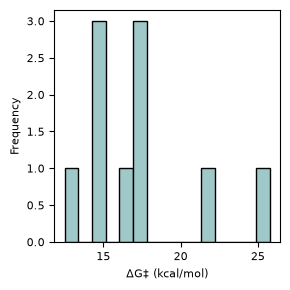

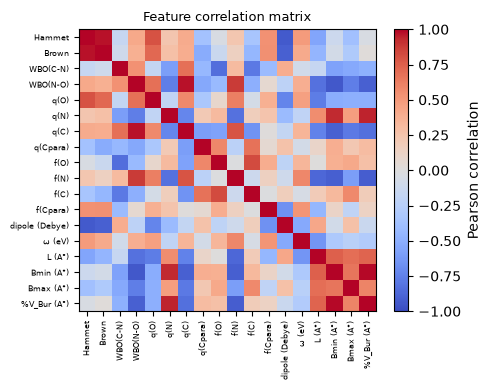

In [4]:
# Load the dataset and display a summary of rows, features, and metadata
X, y, metadata = load_regression_data(
    excel_file=excel_file,
    sheet_name=sheet_name,
    target_column=target_column,
    id_columns=id_columns,
    drop_columns=drop_columns,
    metadata_columns=additional_metadata_columns, round_digits=round_digits)
print(f"Loaded dataset: {X.shape[0]} rows, {X.shape[1]} features.")
if (show_summary_tables or show_detailed_tables) and not metadata.empty:
    show_table( "Metadata preview", "Identifier and split-related columns retained outside the descriptor matrix.", metadata, rows=table_preview_rows)


# Optionally plot the overall distribution of the response variable
if plot_response_distribution:
    plot_target_distribution(
        y=y,
        target_label=target_column,
        results_dir=results_dir,
        output_prefix=output_prefix,
        bins=response_distribution_bins,
        save_figures=save_figures,
        show_figures=show_figures,
        plot_settings=plot_settings,
    )

# Optionally plot the correlation matrix of the features
if plot_correlation_matrix:
    plot_correlation_heatmap( X=X, results_dir=results_dir, output_prefix=output_prefix, save_figures=save_figures, show_figures=show_figures, plot_settings=plot_settings)


## 5. Nested training and validation
For each outer fold, models are fitted on the **training set** and evaluated on the held-out **validation set**. These validation predictions are technically out-of-fold (OOF) predictions. The term **external test** is reserved for a separate file never used during nested cross-validation.


In [5]:
# Run the nested cross-validation workflow
results = run_nested_regression(
    X=X,
    y=y,
    metadata=metadata,
    model_names=model_names,
    outer_n_splits=outer_n_splits,
    outer_n_repeats=outer_n_repeats,
    inner_cv_splits=inner_cv_splits,
    inner_cv_repeats=inner_cv_repeats,
    min_features=min_features,
    max_features_cap=max_features_cap,
    corr_threshold=corr_threshold,
    n_trials=n_trials,
    overfit_penalty_weight=overfit_penalty_weight,
    optimize_metric=optimize_metric,
    random_state=random_state,
    outer_split_strategy=outer_split_strategy,
    inner_split_strategy=inner_split_strategy,
    split_group_columns=split_group_columns,
    y_stratify_bins=y_stratify_bins,
    ks_test_fraction=ks_test_fraction,
    held_out_groups=held_out_groups,
    predefined_split_column=predefined_split_column,
    predefined_train_label=predefined_train_label,
    export_split_indices=export_split_indices,
    export_test_groups=export_test_groups,
    max_test_groups_to_export=max_test_groups_to_export,
    rfe_step=rfe_step, n_jobs=n_jobs, one_se=one_se,
    verbose=True,)
print("Nested cross-validation done.")

# Optionally visualize the summary and detailed tables of results
if show_summary_tables:
    show_table(
        "Model ranking from mean validation predictions",
        "Primary comparison table. Models are ranked using the selected regression metric across repeated outer validation folds.",
        results["summary_mean"],)

if show_detailed_tables:
    show_table(
        "Training/validation cross-validation summary",
        "Mean and variability across outer folds. This shows how stable each model is across the resampling procedure.",
        results["summary_nested"],)
    show_table(
        "Outer split manifest",
        "Composition and size of each outer train/test split. Use it to verify that the requested split strategy was applied correctly.",
        results["split_manifest"],
        rows=table_preview_rows,)
    show_table(
        "Hyperparameters and selected features by fold",
        "Technical table containing the best Optuna parameters, feature-selection method and selected descriptors for every outer fold.",
        results["params"],)
    show_table( "Mean training metrics", "Average in-fold training performance. Compare with the test metrics to diagnose overfitting.", results["train_mean"],)
    show_table( "Mean outer-test metrics", "Average performance obtained independently on each outer test fold.", results["test_mean"],)
    show_table(
        "Repeated OOF predictions",
        "One row per sample occurrence in an outer test fold. Samples appear multiple times when repeated CV is used.",
        results["predictions_all"],
        rows=table_preview_rows,)
    show_table(
        "Mean OOF prediction per sample",
        "One row per sample after averaging all of its repeated out-of-fold predictions.",
        results["predictions_mean"],
        rows=table_preview_rows,)
    show_table( "Feature-selection frequency", "How often each descriptor was selected across outer folds for each model family.", results["feature_frequency"], rows=30,)
    show_table( "Selector frequency", "How often each feature-selection algorithm was chosen by Optuna for each model family.", results["selector_frequency"],)

    print("Representative features by model:")
    for model_name, features in results["representative_features"].items():
        print(f"  {model_name}: {features[:max_features_cap]}")



Starting MLR
  Fold 1/4
  Fold 2/4
  Fold 3/4
  Fold 4/4

Starting Ridge
  Fold 1/4
  Fold 2/4
  Fold 3/4
  Fold 4/4

Starting Lasso
  Fold 1/4
  Fold 2/4
  Fold 3/4
  Fold 4/4
Nested cross-validation done.


### Model ranking from mean validation predictions
Primary comparison table. Models are ranked using the selected regression metric across repeated outer validation folds.

,Model,Model_selection_metric,R2_mean_oof_prediction_per_sample,RMSE_mean_oof_prediction_per_sample,MAE_mean_oof_prediction_per_sample,r2_mean_prediction,rmse_mean_prediction,mae_mean_prediction
1,MLR,r2,0.918622,1.066459,0.878577,0.918622,1.066459,0.878577
2,Ridge,r2,0.371917,2.962783,2.170575,0.371917,2.962783,2.170575
0,Lasso,r2,-0.036762,3.806545,2.815718,-0.036762,3.806545,2.815718


## 6. Export complete numerical results
Writes the full configuration and all result tables to one Excel workbook, including tables not displayed inline.


In [6]:
# Save Excel sheet with all results
configuration = {
    "excel_file": excel_file, "sheet_name": sheet_name, "target_column": target_column,
    "id_columns": id_columns, "drop_columns": drop_columns, "output_prefix": output_prefix,
    "optimize_metric": optimize_metric,
    "outer_n_splits": outer_n_splits, "outer_n_repeats": outer_n_repeats,
    "inner_cv_splits": inner_cv_splits, "inner_cv_repeats": inner_cv_repeats,
    "outer_split_strategy": outer_split_strategy, "inner_split_strategy": inner_split_strategy,
    "y_stratify_bins": y_stratify_bins, "ks_test_fraction": ks_test_fraction,
    "split_group_columns": split_group_columns, "held_out_groups": held_out_groups,
    "predefined_split_column": predefined_split_column, "predefined_train_label": predefined_train_label,
    "n_trials": n_trials, "min_features": min_features, "max_features_cap": max_features_cap,
    "corr_threshold": corr_threshold, "overfit_penalty_weight": overfit_penalty_weight,
    "model_names": model_names, "random_state": random_state, "rfe_step": rfe_step, "n_jobs": n_jobs, "optuna_jobs": optuna_jobs, "one_se": one_se, "round_digits": round_digits,
    "plot_settings": plot_settings, "parity_axis_limits": parity_axis_limits,}

excel_output = export_workflow_results( results=results, output_file=results_dir / f"ML_results_{output_prefix}.xlsx", save_excel=save_excel, configuration=configuration,)

print(f"Saved Excel results to: {excel_output}" if excel_output else "Excel export disabled.")


Saved Excel results to: Results/workflow_example_261102_regression/ML_results_workflow_example_260814_regression.xlsx


## 7. Final training/validation models as plots
**Training** = data used to fit a fold model; **Validation** = held-out outer-fold data (OOF); **Full dataset** = final ensemble predictions on all original observations; **External test** = a separate unseen labeled dataset.


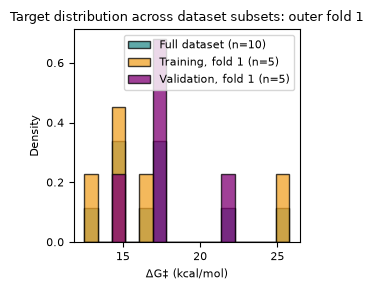

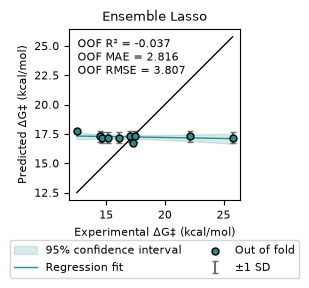

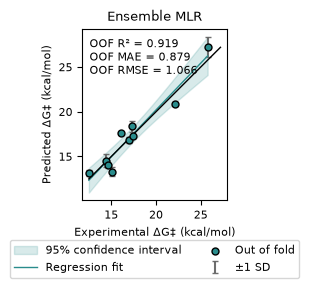

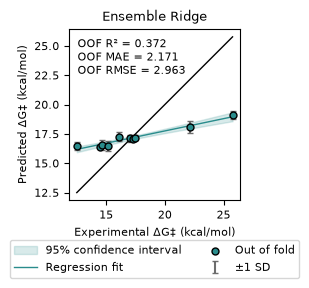

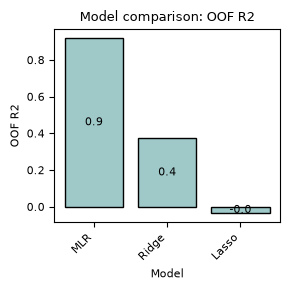

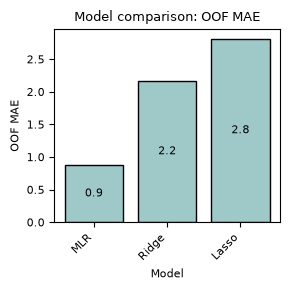

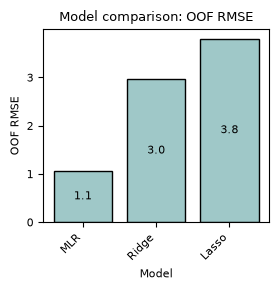

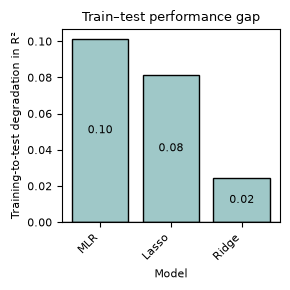

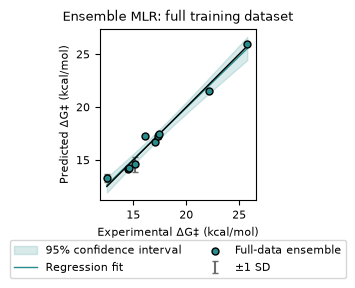

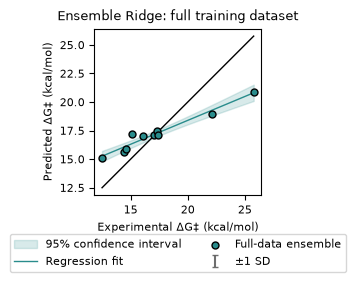

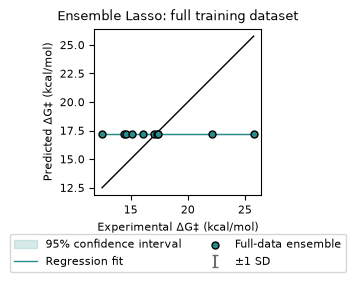

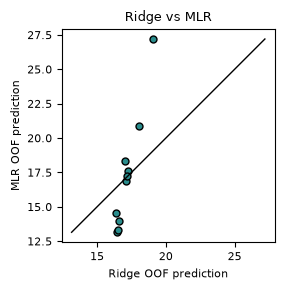

In [35]:
# Show requested plots and visualizations
if plot_split_distribution:
    plot_target_split_distribution(
        y=y,
        split_assignments=results["split_assignments"],
        fold=split_distribution_fold,
        results_dir=results_dir,
        output_prefix=output_prefix,
        target_label=target_column,
        bins=split_distribution_bins,
        density=split_distribution_density,
        save_figures=save_figures,
        show_figures=show_figures,
        plot_settings=plot_settings,)
plot_oof_parity(
    results=results,
    results_dir=results_dir,
    output_prefix=output_prefix,
    target_label=target_column,
    save_figures=True,
    show_figures=True,
    axis_limits=None,
    plot_settings=plot_settings,
    )
if plot_model_comparisons:
    for metric_name in ["R2", "MAE", "RMSE"]:
        plot_model_metric_comparison(
            results=results, results_dir=results_dir, output_prefix=output_prefix,
            metric=metric_name, save_figures=save_figures, show_figures=show_figures,
            plot_settings=plot_settings,)
if plot_train_test_gap:
    plot_overfitting_gap(
        results=results, results_dir=results_dir, output_prefix=output_prefix,
        metric=optimize_metric, save_figures=save_figures, show_figures=show_figures, plot_settings=plot_settings,)
if plot_full_training_ensemble:
    plot_full_ensemble_parity(
    results=results,
    results_dir=results_dir,
    output_prefix=output_prefix,
    target_label=target_column,
    model_names=None,
    save_figures=True,
    show_figures=True,
    axis_limits=None,
    show_prediction_errorbars=True,
    plot_settings=plot_settings,
    )   
if show_detailed_tables:
    show_table(
        "Full-training ensemble predictions",
        "Predictions of the final full-training ensemble on the complete training dataset. These are in-sample predictions and must not be used as the unbiased performance estimate.",
        results["predictions_full_ensemble"],
        rows=table_preview_rows,)
if plot_pairwise_model_comparison:
    plot_model_prediction_comparison(
        results=results, model_x=comparison_model_x, model_y=comparison_model_y,
        results_dir=results_dir, output_prefix=output_prefix,
        save_figures=save_figures, show_figures=show_figures,
        plot_settings=plot_settings,)


## 8. Feature selection, descriptor exploration, and SHAP
Shows feature-selection frequencies, descriptor histograms, descriptor-versus-target scatter plots, descriptor-pair panels and SHAP interpretation of the final ensemble.


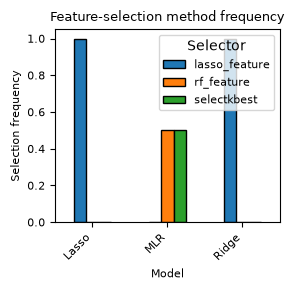

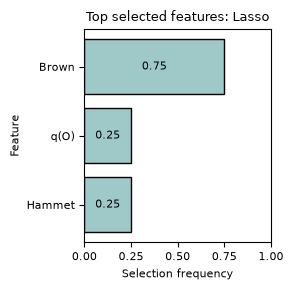

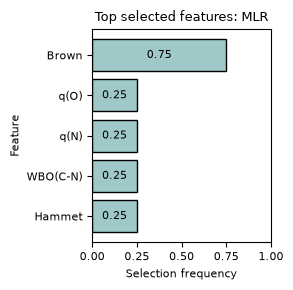

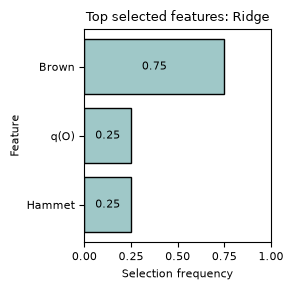

### Univariate feature-target correlations
Descriptors ranked by their individual association with the response. These values describe univariate relationships, not multivariate model importance.

,Feature,Correlation,Abs_Correlation,Univariate_R2,P_Value,N,Method
0,Brown,-0.980184,0.980184,0.960761,6.586593e-07,10,pearson
1,Hammet,-0.965485,0.965485,0.932161,5.955463e-06,10,pearson
2,dipole (Debye),0.871233,0.871233,0.759046,1.026752e-03,10,pearson
3,q(O),-0.801535,0.801535,0.642459,5.300886e-03,10,pearson
4,q(Cpara),0.545527,0.545527,0.297600,1.028773e-01,10,pearson
5,L (A°),0.531688,0.531688,0.282692,1.137084e-01,10,pearson
6,WBO(N-O),-0.501566,0.501566,0.251568,1.396730e-01,10,pearson


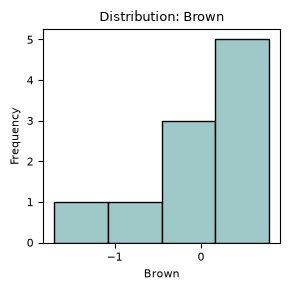

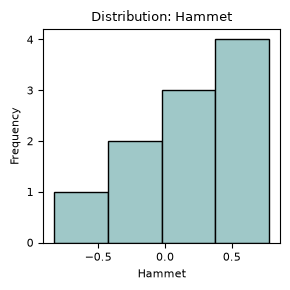

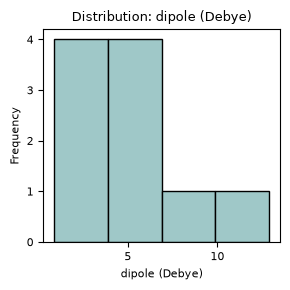

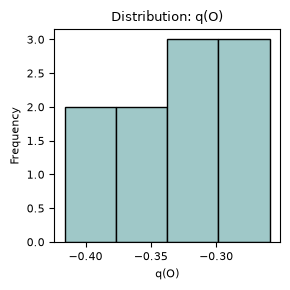

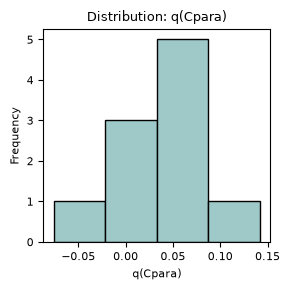

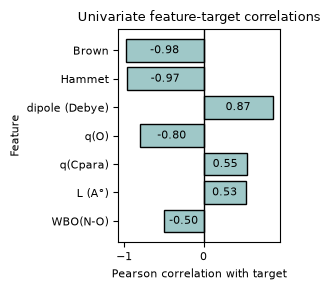

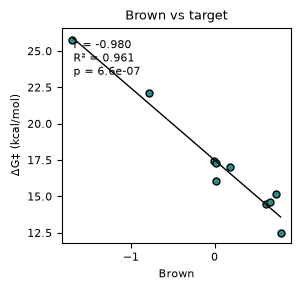

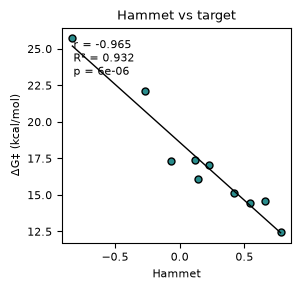

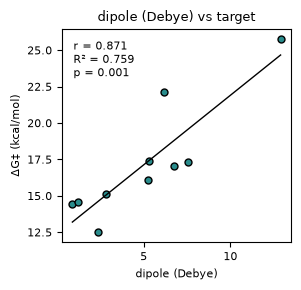

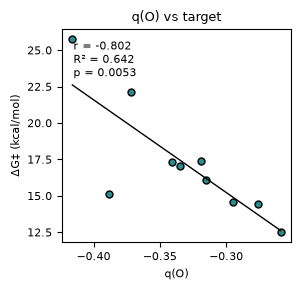

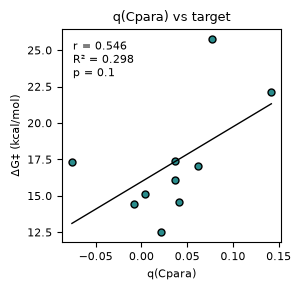

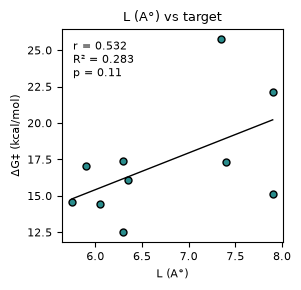

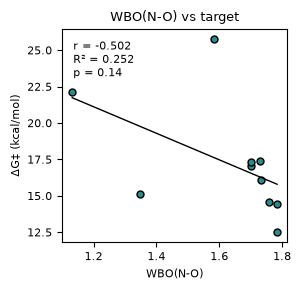

Feature pairs: [('Brown', 'Hammet'), ('Hammet', 'WBO(C-N)'), ('WBO(C-N)', 'q(N)'), ('q(N)', 'q(O)'), ('q(O)', 'ω (eV)')]


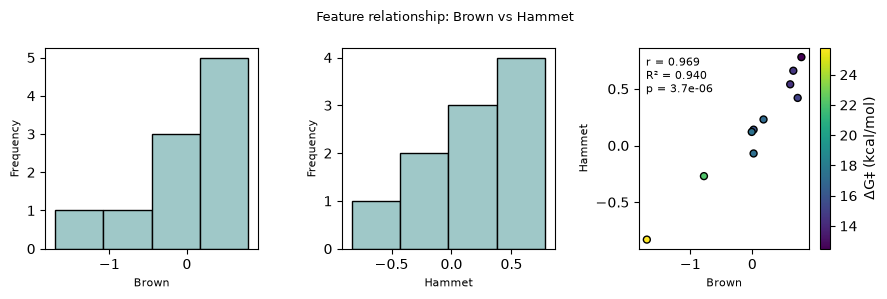

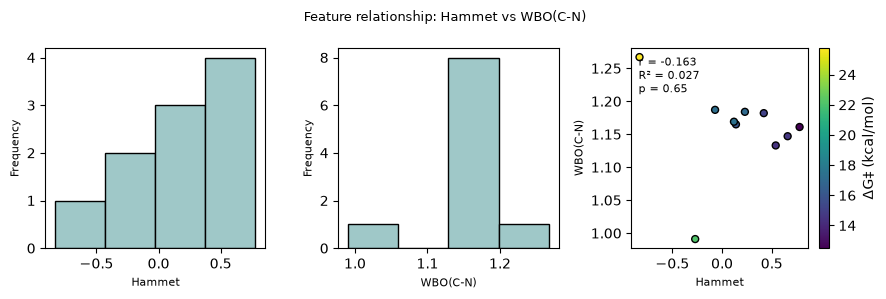

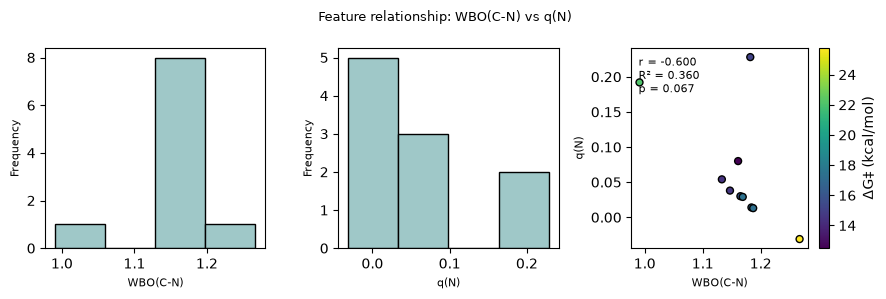

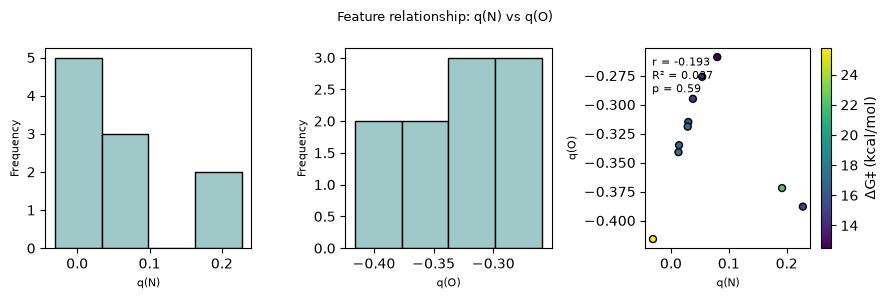

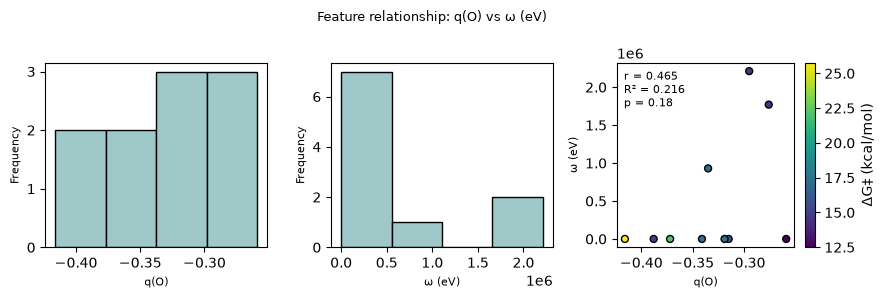

SHAP disabled.


In [36]:
# Show feature selection and correlation results
if plot_selector_frequencies:
    plot_selector_frequency(
        results=results, results_dir=results_dir, output_prefix=output_prefix,
        save_figures=save_figures, show_figures=show_figures, plot_settings=plot_settings,)
if plot_feature_frequencies:
    plot_feature_frequency(
        results=results, results_dir=results_dir, output_prefix=output_prefix,
        top_n=feature_frequency_top_n, save_figures=save_figures,
        show_figures=show_figures, plot_settings=plot_settings,)
feature_target_correlations = compute_feature_target_correlations( X=X, y=y, method=feature_target_method)
if show_summary_tables or show_detailed_tables:
    show_table(
        "Univariate feature-target correlations",
        "Descriptors ranked by their individual association with the response. These values describe univariate relationships, not multivariate model importance.",
        feature_target_correlations,
        rows=feature_target_top_n,)
if save_excel:
    feature_target_correlations.to_excel( results_dir / f"Feature_target_correlations_{output_prefix}.xlsx", index=False)
if feature_histogram_manual:
    histogram_features = feature_histogram_manual
else:
    histogram_features = feature_target_correlations["Feature"].head(feature_histogram_top_n).tolist()
if plot_feature_histograms_enabled:
    plot_feature_histograms(
        X=X, results_dir=results_dir, output_prefix=output_prefix,
        features=histogram_features, bins=feature_histogram_bins,
        save_figures=save_figures, show_figures=show_figures, plot_settings=plot_settings,)
if plot_feature_target_correlations_enabled:
    plot_feature_target_correlations(
        correlation_table=feature_target_correlations,
        results_dir=results_dir, output_prefix=output_prefix, top_n=feature_target_top_n,
        save_figures=save_figures, show_figures=show_figures, plot_settings=plot_settings,)
if plot_feature_target_scatter_enabled:
    plot_feature_target_scatter(
        X=X,
        y=y,
        correlation_table=feature_target_correlations,
        results_dir=results_dir,
        output_prefix=output_prefix,
        top_n=feature_target_top_n,
        features=feature_target_scatter_manual or None,
        save_figures=save_figures,
        show_figures=show_figures,
        plot_settings=plot_settings,)
if feature_pair_mode == "manual":
    feature_pairs = feature_pairs_manual
elif feature_pair_mode == "correlation":
    pair_features = feature_target_correlations["Feature"].head(feature_pair_top_n).tolist()
    feature_pairs = make_feature_pairs( pair_features, max_pairs=feature_pair_max_pairs, adjacent_only=feature_pair_adjacent_only,)
elif feature_pair_mode == "representative":
    resolved_model = ( results["summary_mean"].iloc[0]["Model"] if feature_pair_model == "best" else feature_pair_model)
    pair_features = results["representative_features"][resolved_model][:feature_pair_top_n]
    feature_pairs = make_feature_pairs( pair_features, max_pairs=feature_pair_max_pairs, adjacent_only=feature_pair_adjacent_only,)
else:
    raise ValueError("feature_pair_mode must be representative, correlation, or manual.")
print("Feature pairs:", feature_pairs)
if plot_feature_pairs_enabled and feature_pairs:
    plot_feature_pairs(
        X=X, y=y, feature_pairs=feature_pairs,
        results_dir=results_dir, output_prefix=output_prefix,
        bins=feature_histogram_bins, color_by_target=feature_pair_color_by_target,
        annotate_ids=None, save_figures=save_figures,
        show_figures=show_figures, plot_settings=plot_settings,)
if shap_model_names == "best":
    resolved_shap_models = [results["summary_mean"].iloc[0]["Model"]]
elif shap_model_names == "all":
    resolved_shap_models = list(results["models_dict"])
else:
    resolved_shap_models = list(shap_model_names)
shap_results = {}
if run_shap:
    for model_name in resolved_shap_models:
        shap_result = compute_ensemble_shap(
            ensemble_model=results["full_models_dict"][model_name],
            X_background=X,
            X_explain=X.reset_index(drop=True),
            model_name=model_name,
            dataset_labels=["Training"] * len(X),
            sample_ids=list(range(len(X))),
            background_size=shap_background_size,
            max_evals=shap_max_evals,
            random_state=random_state,)
        shap_results[model_name] = shap_result
        plot_ensemble_shap(
            shap_result=shap_result, model_name=model_name,
            results_dir=results_dir, output_prefix=output_prefix,
            max_display=shap_max_display, save_figures=save_figures,
            show_figures=show_figures, plot_settings=plot_settings,)
        if show_summary_tables:
            show_table(
                f"Ensemble SHAP importance — {model_name}",
                "Mean absolute SHAP values for the final full-training ensemble. Larger values indicate a greater average contribution to the ensemble predictions.",
                shap_result["importance"],
                rows=shap_max_display,)
    shap_output = save_ensemble_shap_results( shap_results=shap_results, output_file=results_dir / f"Ensemble_SHAP_train_{output_prefix}.xlsx", save_excel=save_excel,)
    print(f"Saved ensemble SHAP results to: {shap_output}" if shap_output else "SHAP export disabled.")
else:
    print("SHAP disabled.")


## 9. Optional virtual screening
Predicts an unlabeled or partially labeled screening file with the final fold ensemble. Disabled by default.


Saved virtual-screening predictions to: Results/workflow_example_261102_regression/Virtual_screening_workflow_example_260814_regression.xlsx


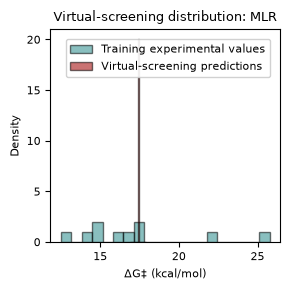

### Virtual-screening predictions
Predictions and ensemble-member standard deviation for the screening dataset.

,Nitroso,Hammet,Brown,WBO(C-N),WBO(N-O),q(O),q(N),q(C),q(Cpara),f(O),...,dipole (Debye),ω (eV),L (A°),Bmin (A°),Bmax (A°),%V_Bur (A°),Predicted_MLR,Prediction_STD_MLR,CI95_Lower_MLR,CI95_Upper_MLR
0,CH2Cl,0.12,-0.01,1.169,1.729,-0.319,0.029,0.059,0.037,0.202,...,5.306,4.2141,6.3,1.5,7.281,24.95,17.418112,0.128613,17.166029,17.670194


In [9]:
# Optionally run virtual screening on an external dataset
run_virtual_screening = True
screening_file = Path("./InputData/Example.xlsx")
screening_sheet = "Screening"
screening_model_names = "best"  # best, all, or a list
plot_screening_distribution = True
screening_histogram_bins = 20
if run_virtual_screening:
    if screening_model_names == "best":
        resolved_screening_models = [results["summary_mean"].iloc[0]["Model"]]
    elif screening_model_names == "all":
        resolved_screening_models = list(results["models_dict"])
    else:
        resolved_screening_models = list(screening_model_names)
    df_screening = pd.read_excel(screening_file, sheet_name=screening_sheet)
    screening_predictions, _ = evaluate_external_dataset(
        df_external=df_screening, training_columns=X.columns,
        models_dict=results["full_models_dict"], target_column=target_column,
        id_columns=id_columns, drop_columns=drop_columns,
        model_names=resolved_screening_models, include_prediction_std=True,)
    if save_excel:
        screening_output = results_dir / f"Virtual_screening_{output_prefix}.xlsx"
        screening_predictions.to_excel(screening_output, index=False)
        print(f"Saved virtual-screening predictions to: {screening_output}")
    if plot_screening_distribution:
        plot_virtual_screening_distribution(
            y_training=y, screening_results=screening_predictions,
            model_names=resolved_screening_models, results_dir=results_dir,
            output_prefix=output_prefix, target_label=target_column,
            bins=screening_histogram_bins, save_figures=save_figures,
            show_figures=show_figures, plot_settings=plot_settings,)
    if show_summary_tables:
        show_table(
            "Virtual-screening predictions",
            "Predictions and ensemble-member standard deviation for the screening dataset.",
            screening_predictions,
            rows=table_preview_rows,)
else:
    print("Virtual screening disabled.")


## 10. Optional external test
Evaluates a completely unseen labeled dataset. The external-test scatter is compared with predictions of the final ensemble on the **full dataset**.


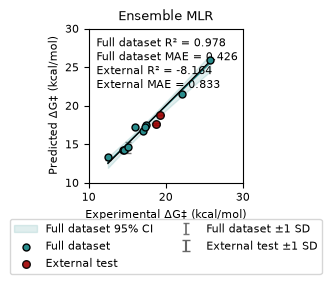

### External-test metrics
Performance of the final full-training ensemble on the completely unseen external dataset.

,Model,N_Ensemble_Members,R2_external,RMSE_external,MAE_external
0,MLR,4,-8.164142,0.883309,0.832969


### External-test predictions
Observed values, ensemble predictions and prediction standard deviation for the external dataset.

,Nitroso,ΔG‡ (kcal/mol),G(Nu) (Ha),G(nitroso) (Ha),G(TS) (Ha),G(TS_true) (Ha),Hammet,Brown,WBO(C-N),WBO(N-O),...,dipole (Debye),ω (eV),L (A°),Bmin (A°),Bmax (A°),%V_Bur (A°),Predicted_MLR,Prediction_STD_MLR,CI95_Lower_MLR,CI95_Upper_MLR
0,Me,19.314450,-793.473,-400.82398,-1194.2662,NaN,-0.17,-0.31,1.464,1.625,...,6.960,3.8710,4.25,1.686,5.607,44.94,18.775415,0.026444,18.723585,18.827245
1,SH,18.730875,-793.473,-759.72375,-1553.1669,NaN,0.15,-0.03,1.118,1.322,...,6.882,3.8051,4.50,1.650,5.720,44.92,17.603972,0.148353,17.313200,17.894744


In [34]:
# Optionally run an external test on a completely unseen dataset
run_external_test = True
external_file = Path("./InputData/Example.xlsx")
external_sheet = "Test"
external_model_names = "best"  # best, all, or a list
external_label = "External test"
if run_external_test:
    if external_model_names == "best":
        resolved_external_models = [results["summary_mean"].iloc[0]["Model"]]
    elif external_model_names == "all":
        resolved_external_models = list(results["models_dict"])
    else:
        resolved_external_models = list(external_model_names)
    df_external = pd.read_excel(external_file, sheet_name=external_sheet)
    external_predictions, external_metrics = evaluate_external_dataset(
        df_external=df_external, training_columns=X.columns,
        models_dict=results["full_models_dict"], target_column=target_column,
        id_columns=id_columns, drop_columns=drop_columns,
        model_names=resolved_external_models, include_prediction_std=True,)
    combined_training_external = combine_training_and_external_predictions(
        results=results, external_results=external_predictions,
        target_column=target_column, model_names=resolved_external_models,)
    save_external_results(
        detailed_results=external_predictions, metrics=external_metrics,
        output_file=results_dir / f"External_test_{output_prefix}.xlsx",
        save_excel=save_excel,
        combined_training_external=combined_training_external,)
    plot_external_overlay(
        results=results, external_results=external_predictions,
        external_metrics=external_metrics, target_column=target_column,
        results_dir=results_dir, output_prefix=output_prefix,
        external_label=external_label, model_names=resolved_external_models,
        save_figures=save_figures, show_figures=show_figures,
        axis_limits=parity_axis_limits, plot_settings=plot_settings,
        training_reference="full_dataset",)
    if show_summary_tables:
        show_table( "External-test metrics", "Performance of the final full-training ensemble on the completely unseen external dataset.", external_metrics,)
        show_table(
            "External-test predictions",
            "Observed values, ensemble predictions and prediction standard deviation for the external dataset.",
            external_predictions,
            rows=table_preview_rows,)
    if show_detailed_tables:
        show_table(
            "Combined validation and external predictions",
            "Long-format table joining training-validation predictions and external-test predictions for downstream analysis.",
            combined_training_external,
            rows=table_preview_rows,)
else:
    print("External test disabled.")